# Task 6: Deep Learning Fundamentals

## Introduction

A deep neural network is a stack of layers that learns to map inputs to outputs by adjusting its weights and biases. Training one means repeating a cycle: make predictions, measure the error, compute gradients, and update the weights to reduce that error. Four design choices control how well this cycle works:

| Component | Role in training | Covered in this task |
|:---|:---|:---|
| **Activation functions** | Add non-linearity so the network can learn complex patterns | Sigmoid, Tanh, ReLU, Leaky ReLU |
| **Loss functions** | Measure how far the predictions are from the true values | MSE, Binary Cross Entropy, Categorical Cross Entropy |
| **Optimizers** | Decide how the weights are updated using the gradients | Gradient Descent, SGD, RMSProp, Adam |
| **Regularization** | Reduce overfitting so the model generalizes to unseen data | Dropout, Batch Normalization, Early Stopping |

### Objective

- Understand the core components involved in training deep neural networks.
- Use one reusable feedforward network (building on Task 5) to run controlled experiments on **Fashion-MNIST**.
- Compare activation functions, optimizers (SGD vs Adam), and the effect of dropout on overfitting.
- Interpret training and validation curves to draw conclusions.

In [2]:
# Imports

import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset, random_split


# Device selection

device = "cuda" if torch.cuda.is_available() else "cpu"


# Reproducibility

torch.manual_seed(42)
np.random.seed(42)


# Print the environment details

print("PyTorch version:", torch.__version__)
print("Using device:", device)

PyTorch version: 2.12.0+cpu
Using device: cpu


## 1. Activation Functions

An activation function is applied to the output of each neuron. Without it, a stack of linear layers collapses into a single linear transformation, so the network could not learn non-linear patterns.

| Function | Formula | Output range | Advantages | Disadvantages |
|:---|:---|:---:|:---|:---|
| **Sigmoid** | $\sigma(x) = \dfrac{1}{1 + e^{-x}}$ | (0, 1) | Smooth; output reads as a probability | Saturates for large \|x\| (vanishing gradient); maximum gradient is only 0.25; not zero-centered |
| **Tanh** | $\tanh(x) = \dfrac{e^{x} - e^{-x}}{e^{x} + e^{-x}}$ | (-1, 1) | Zero-centered; stronger gradient than sigmoid (max 1) | Still saturates for large \|x\| |
| **ReLU** | $\max(0, x)$ | [0, ∞) | Cheap to compute; no saturation for positive inputs; trains fast | "Dying ReLU": neurons stuck at 0 stop learning |
| **Leaky ReLU** | $x$ if $x > 0$, else $\alpha x$ (e.g. $\alpha = 0.01$) | (-∞, ∞) | Small negative slope keeps gradients alive, avoiding dying neurons | Extra hyperparameter $\alpha$ |

**Reading the plot below**
- **Left:** the four activation functions on one graph.
- **Right:** their derivatives (computed with Autograd). Sigmoid and Tanh have gradients near 0 at the edges, which is the cause of the vanishing gradient problem. ReLU keeps a constant gradient of 1 for positive inputs.

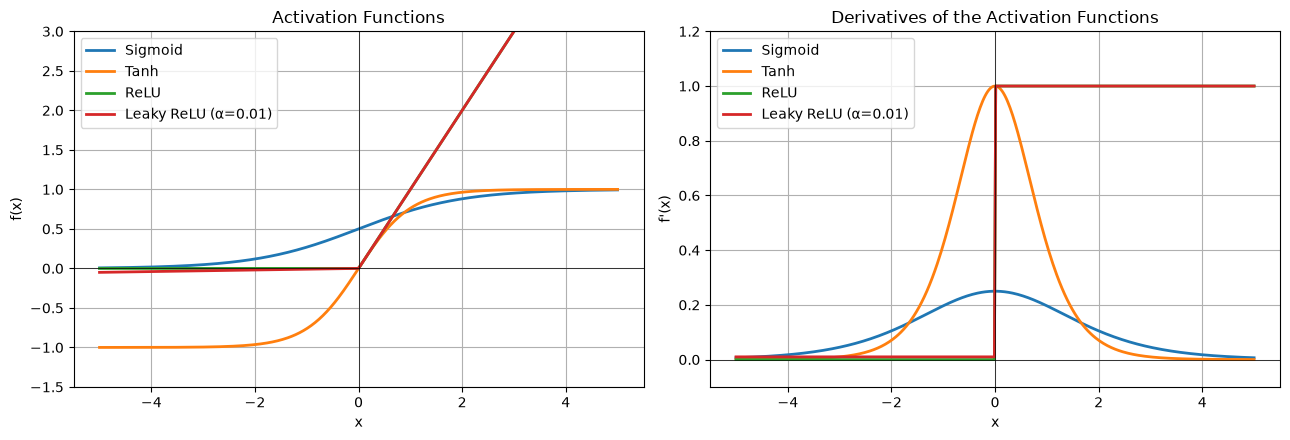

In [3]:
# Input range for plotting (requires_grad so Autograd can compute derivatives)

x = torch.linspace(-5, 5, 400, requires_grad=True)


# Define the four activation functions

activations = {
    "Sigmoid": torch.sigmoid,
    "Tanh": torch.tanh,
    "ReLU": F.relu,
    "Leaky ReLU (α=0.01)": lambda t: F.leaky_relu(t, negative_slope=0.01),
}


# Plot activations (left) and their derivatives (right)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for name, fn in activations.items():
    y = fn(x)                                          # forward pass
    grad, = torch.autograd.grad(y.sum(), x)            # derivative via Autograd

    axes[0].plot(x.detach(), y.detach(), label=name, linewidth=2)
    axes[1].plot(x.detach(), grad, label=name, linewidth=2)

axes[0].set_title("Activation Functions")
axes[0].set_xlabel("x")
axes[0].set_ylabel("f(x)")
axes[0].set_ylim(-1.5, 3)                              # clip ReLU so small curves stay visible
axes[0].axhline(0, color="black", linewidth=0.5)
axes[0].axvline(0, color="black", linewidth=0.5)
axes[0].legend()
axes[0].grid(True)

axes[1].set_title("Derivatives of the Activation Functions")
axes[1].set_xlabel("x")
axes[1].set_ylabel("f'(x)")
axes[1].set_ylim(-0.1, 1.2)
axes[1].axhline(0, color="black", linewidth=0.5)
axes[1].axvline(0, color="black", linewidth=0.5)
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

## 2. Loss Functions

A loss function measures how far the model's predictions are from the true values. Training minimizes this value.

| Loss | Formula | Used for | PyTorch |
|:---|:---|:---|:---|
| **Mean Squared Error (MSE)** | $\dfrac{1}{n}\sum (y - \hat{y})^2$ | Regression | `nn.MSELoss()` |
| **Binary Cross Entropy (BCE)** | $-\left[y\log p + (1-y)\log(1-p)\right]$ | Binary classification (sigmoid output) | `nn.BCELoss()`, `nn.BCEWithLogitsLoss()` |
| **Categorical Cross Entropy (CCE)** | $-\sum_{c} y_c \log p_c$ | Multi-class classification (softmax output) | `nn.CrossEntropyLoss()` |

- `nn.CrossEntropyLoss()` takes **raw logits** and applies softmax internally, so the final layer should not include a softmax.
- BCE and CCE penalize confident wrong predictions far more heavily than MSE, which is why they are preferred for classification.
- The plot below compares BCE and MSE for a single prediction. BCE grows without bound as the prediction moves toward the wrong extreme, while MSE caps at 1.

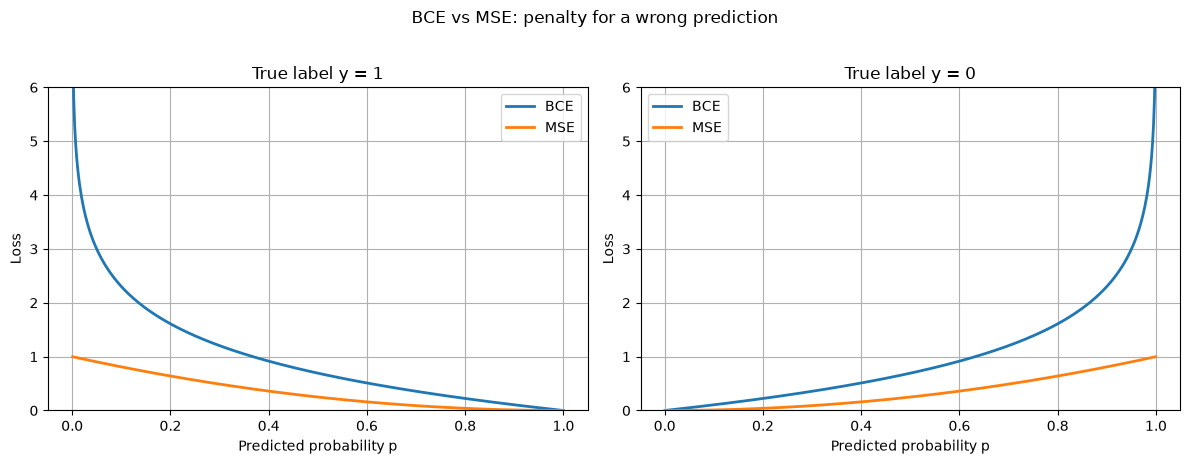

Softmax probabilities: tensor([[0.7856, 0.1753, 0.0391]])
CCE (manual): 0.24131131172180176
CCE (nn.CrossEntropyLoss): 0.24131132662296295


In [4]:
# Predicted probability range (avoid exactly 0 and 1 to prevent log(0))

p = torch.linspace(0.001, 0.999, 500)


# Loss for a single prediction when the true label is 1, and when it is 0

bce_y1 = -torch.log(p)                  # BCE when y = 1
mse_y1 = (1 - p) ** 2                   # MSE when y = 1

bce_y0 = -torch.log(1 - p)              # BCE when y = 0
mse_y0 = p ** 2                         # MSE when y = 0


# Plot BCE vs MSE for both cases

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(p, bce_y1, label="BCE", linewidth=2)
axes[0].plot(p, mse_y1, label="MSE", linewidth=2)
axes[0].set_title("True label y = 1")
axes[0].set_xlabel("Predicted probability p")
axes[0].set_ylabel("Loss")
axes[0].set_ylim(0, 6)
axes[0].legend()
axes[0].grid(True)

axes[1].plot(p, bce_y0, label="BCE", linewidth=2)
axes[1].plot(p, mse_y0, label="MSE", linewidth=2)
axes[1].set_title("True label y = 0")
axes[1].set_xlabel("Predicted probability p")
axes[1].set_ylabel("Loss")
axes[1].set_ylim(0, 6)
axes[1].legend()
axes[1].grid(True)

plt.suptitle("BCE vs MSE: penalty for a wrong prediction", y=1.02)
plt.tight_layout()
plt.show()


# Categorical cross entropy on a 3-class example

logits = torch.tensor([[2.0, 0.5, -1.0]])              # raw model outputs
target = torch.tensor([0])                             # true class is 0

probs = F.softmax(logits, dim=1)                       # convert logits to probabilities
cce_manual = -torch.log(probs[0, target.item()])       # -log(probability of the true class)
cce_torch = F.cross_entropy(logits, target)            # PyTorch applies softmax internally

print("Softmax probabilities:", probs)
print("CCE (manual):", cce_manual.item())
print("CCE (nn.CrossEntropyLoss):", cce_torch.item())

## 3. Optimizers

An optimizer updates the weights using the gradients of the loss. Here $\eta$ is the learning rate and $g$ is the gradient.

| Optimizer | Update idea | Key characteristics |
|:---|:---|:---|
| **Gradient Descent** | $w \leftarrow w - \eta\, g$, with $g$ computed on the **whole dataset** | Stable, but slow and memory-heavy on large data |
| **SGD** | Same rule, with $g$ computed on a **single sample or mini-batch** | Faster, noisier updates; the noise can help escape poor regions. Often used with momentum |
| **RMSProp** | $s \leftarrow \beta s + (1-\beta)g^2$, then $w \leftarrow w - \eta\,\dfrac{g}{\sqrt{s}+\epsilon}$ | Adaptive learning rate per weight; handles steep and flat directions |
| **Adam** | Combines momentum (running average of $g$) with RMSProp-style scaling (running average of $g^2$), with bias correction | Adaptive and fast; a strong default choice |

- The plot below runs SGD, SGD with momentum, RMSProp and Adam from the same starting point on an elongated bowl-shaped surface (steep in one direction, shallow in the other).
- Plain Gradient Descent and SGD follow the same path on a fixed function, since SGD's randomness only comes from mini-batches. That difference is shown in the experiments later, where mini-batches exist.

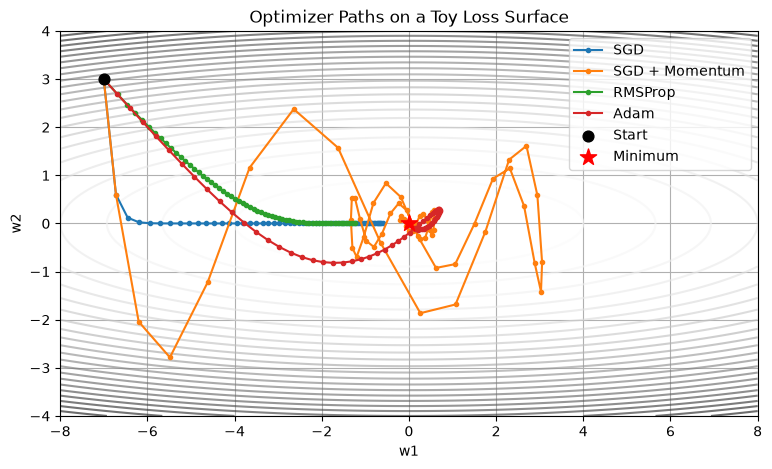

SGD             final distance from minimum: 0.6045
SGD + Momentum  final distance from minimum: 0.2223
RMSProp         final distance from minimum: 1.2428
Adam            final distance from minimum: 0.1464


In [5]:
# Toy loss surface: an elongated bowl, f(x, y) = 0.05x^2 + y^2 (minimum at the origin)

def toy_loss(w):
    return 0.05 * w[0] ** 2 + w[1] ** 2


# Optimizers to compare, all starting from the same point

start = [-7.0, 3.0]
steps = 60

optimizers = {
    "SGD": lambda params: torch.optim.SGD(params, lr=0.4),
    "SGD + Momentum": lambda params: torch.optim.SGD(params, lr=0.4, momentum=0.9),
    "RMSProp": lambda params: torch.optim.RMSprop(params, lr=0.1, alpha=0.9),
    "Adam": lambda params: torch.optim.Adam(params, lr=0.3),
}


# Run each optimizer and record its path

paths = {}
for name, make_opt in optimizers.items():
    w = torch.tensor(start, requires_grad=True)
    opt = make_opt([w])
    path = [w.detach().clone().numpy()]

    for _ in range(steps):
        opt.zero_grad()
        loss = toy_loss(w)
        loss.backward()
        opt.step()
        path.append(w.detach().clone().numpy())

    paths[name] = np.array(path)


# Contour plot of the surface

gx, gy = np.meshgrid(np.linspace(-8, 8, 200), np.linspace(-4, 4, 200))
gz = 0.05 * gx ** 2 + gy ** 2

plt.figure(figsize=(9, 5))
plt.contour(gx, gy, gz, levels=25, cmap="Greys", alpha=0.6)


# Draw each optimizer's path

for name, path in paths.items():
    plt.plot(path[:, 0], path[:, 1], marker="o", markersize=3, label=name)

plt.scatter(*start, color="black", s=60, zorder=5, label="Start")
plt.scatter(0, 0, color="red", marker="*", s=150, zorder=5, label="Minimum")
plt.title("Optimizer Paths on a Toy Loss Surface")
plt.xlabel("w1")
plt.ylabel("w2")
plt.legend()
plt.grid(True)
plt.show()


# Final distance from the minimum after all steps

for name, path in paths.items():
    print(f"{name:15s} final distance from minimum: {np.linalg.norm(path[-1]):.4f}")

## 4. Regularization

Regularization reduces **overfitting**, where the model performs well on training data but poorly on unseen data.

| Technique | How it works | Effect |
|:---|:---|:---|
| **Dropout** | Randomly sets a fraction $p$ of neuron outputs to 0 during training | Stops neurons from co-depending on each other; acts like training an ensemble of smaller networks |
| **Batch Normalization** | Normalizes each layer's inputs over the mini-batch, then applies a learnable scale and shift | Stabilizes and speeds up training; allows higher learning rates; mild regularizing effect |
| **Early Stopping** | Monitors validation loss and stops training when it stops improving | Prevents the model from continuing to fit noise in the training data |

- Dropout and Batch Norm behave differently in training and evaluation, so always call `model.train()` before training and `model.eval()` before evaluating.
- Their effects are demonstrated in the experiments later in this notebook.

## 5. Dataset: Fashion-MNIST

- Fashion-MNIST contains **70,000 grayscale images** of clothing items, each **28 × 28 pixels**: 60,000 for training and 10,000 for testing.
- It is a drop-in replacement for MNIST but harder, which makes differences between activations, optimizers and regularization easier to see.
- Each image is flattened into a vector of **784 pixel values** (0 to 255), with a label from 0 to 9.

| Label | Class | Label | Class |
|:---:|:---|:---:|:---|
| 0 | T-shirt/top | 5 | Sandal |
| 1 | Trouser | 6 | Shirt |
| 2 | Pullover | 7 | Sneaker |
| 3 | Dress | 8 | Bag |
| 4 | Coat | 9 | Ankle boot |

**Preprocessing steps**
- Separate labels from pixels and convert to tensors.
- Scale pixel values to [0, 1], then standardize using the training-set mean and standard deviation.
- Split the 60,000 training images into **54,000 train / 6,000 validation**. The 10,000 test images are kept untouched for final evaluation.
- Wrap the data in `DataLoader`s for mini-batch training.

Train shape: (60000, 785)
Test shape: (10000, 785)
Pixel range: 0.0 to 255.0
Missing values: 0


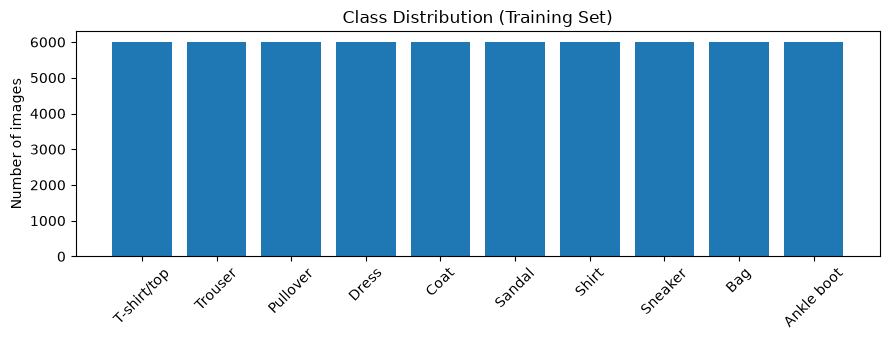

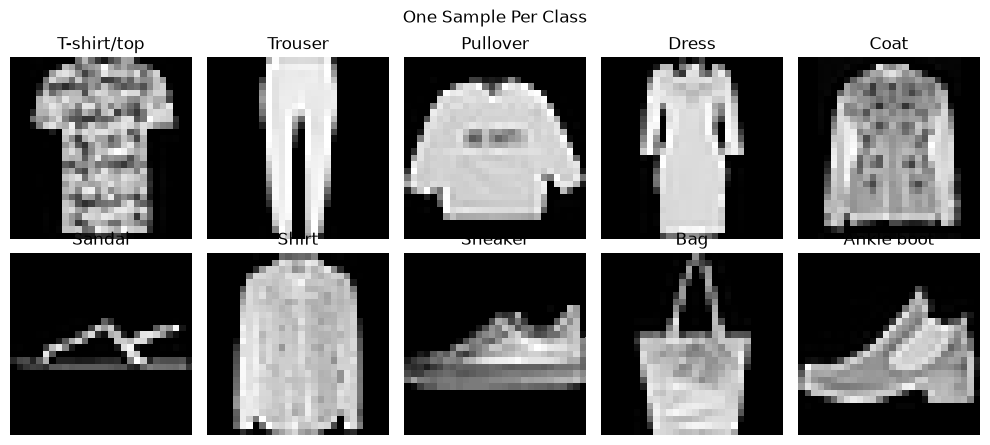

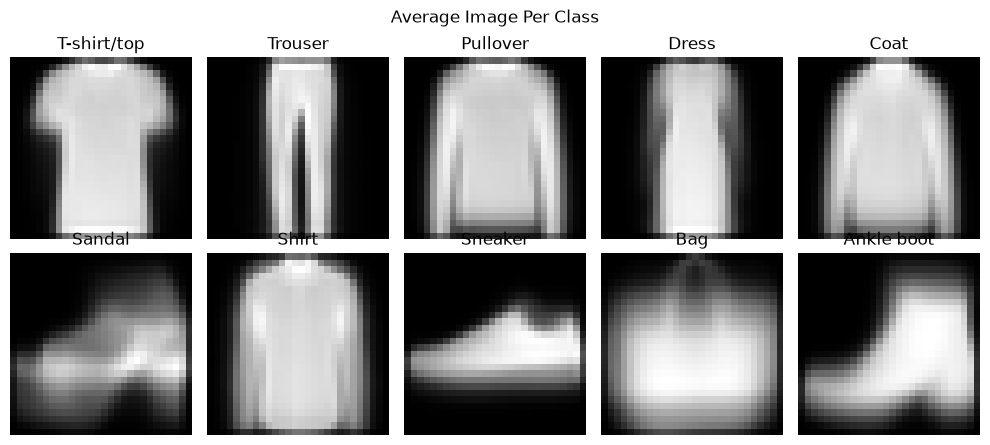

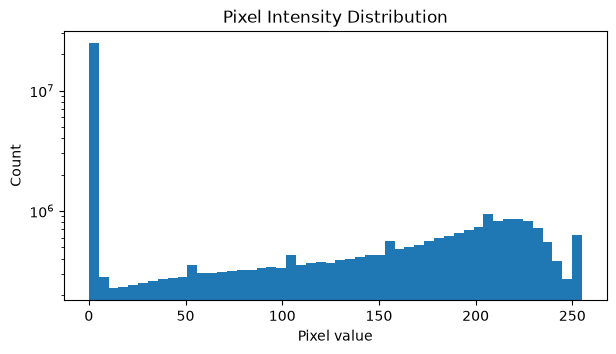

Mean: 0.2861 | Std: 0.3528
Train: 54000 | Validation: 6000 | Test: 10000
One batch: torch.Size([128, 784]) torch.Size([128])


In [6]:
import pandas as pd


DATA_DIR = r"C:\Users\rithy\OneDrive\Desktop\marvel_level3\task6"


# Load the CSV files (first column = label, remaining 784 columns = pixels)

train_df = pd.read_csv(f"{DATA_DIR}/fashion-mnist_train.csv")
test_df = pd.read_csv(f"{DATA_DIR}/fashion-mnist_test.csv")

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)


# Class names

class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]


# Separate labels and pixels

X_train_full = train_df.drop(columns="label").values.astype("float32")
y_train_full = train_df["label"].values
X_test = test_df.drop(columns="label").values.astype("float32")
y_test = test_df["label"].values

print("Pixel range:", X_train_full.min(), "to", X_train_full.max())
print("Missing values:", train_df.isnull().sum().sum())


# EDA: class distribution

counts = np.bincount(y_train_full)
plt.figure(figsize=(9, 3.5))
plt.bar(class_names, counts)
plt.xticks(rotation=45)
plt.ylabel("Number of images")
plt.title("Class Distribution (Training Set)")
plt.tight_layout()
plt.show()


# EDA: sample images

fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for i, ax in enumerate(axes.flat):
    idx = np.where(y_train_full == i)[0][0]            # first image of each class
    ax.imshow(X_train_full[idx].reshape(28, 28), cmap="gray")
    ax.set_title(class_names[i])
    ax.axis("off")
plt.suptitle("One Sample Per Class")
plt.tight_layout()
plt.show()


# EDA: average image per class

fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_train_full[y_train_full == i].mean(axis=0).reshape(28, 28), cmap="gray")
    ax.set_title(class_names[i])
    ax.axis("off")
plt.suptitle("Average Image Per Class")
plt.tight_layout()
plt.show()


# EDA: pixel intensity distribution

plt.figure(figsize=(7, 3.5))
plt.hist(X_train_full.flatten(), bins=50)
plt.xlabel("Pixel value")
plt.ylabel("Count")
plt.title("Pixel Intensity Distribution")
plt.yscale("log")
plt.show()


# Preprocessing: scale to [0, 1], then standardize with training statistics

X_train_full /= 255.0
X_test /= 255.0

mean, std = X_train_full.mean(), X_train_full.std()
X_train_full = (X_train_full - mean) / std
X_test = (X_test - mean) / std                         # use TRAIN statistics only
print(f"Mean: {mean:.4f} | Std: {std:.4f}")


# Convert to tensors

X_train_full = torch.tensor(X_train_full)
y_train_full = torch.tensor(y_train, dtype=torch.long) if False else torch.tensor(y_train_full, dtype=torch.long)
X_test = torch.tensor(X_test)
y_test = torch.tensor(y_test, dtype=torch.long)


# Train / validation split (54,000 / 6,000)

full_train = TensorDataset(X_train_full, y_train_full)
train_ds, val_ds = random_split(full_train, [54000, 6000],
                                generator=torch.Generator().manual_seed(42))
test_ds = TensorDataset(X_test, y_test)

print("Train:", len(train_ds), "| Validation:", len(val_ds), "| Test:", len(test_ds))


# DataLoaders

batch_size = 128
train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=batch_size)
test_loader = DataLoader(test_ds, batch_size=batch_size)

xb, yb = next(iter(train_loader))
print("One batch:", xb.shape, yb.shape)                # (128, 784) and (128,)

### 6. Baseline Model - Feedforward Network

- A feedforward network (stacked `Linear` layers), as in Task 5, now written as a **flexible class** so every experiment reuses it.
- Layer pattern per hidden block: `Linear → (BatchNorm) → Activation → (Dropout)`. The final layer outputs raw logits.

| Parameter | Options | Used in |
|:---|:---|:---|
| `activation` | `sigmoid`, `tanh`, `relu`, `leaky_relu` | Experiment A |
| `dropout` | 0.0 (off), 0.2, 0.5, ... | Experiment C |
| `batch_norm` | `True` / `False` | Experiment E |
| `hidden_dims`, `num_outputs` | Layer sizes; 10 classes (or 1 for binary) | All |

**`train_model(...)`** trains for a number of epochs and returns the per-epoch history.

| Argument | Purpose |
|:---|:---|
| `optimizer_name` | `gd`, `sgd`, `sgd_momentum`, `rmsprop`, `adam` (Experiment B) |
| `loss_type` | `ce` (multi-class), `bce`, `mse` (Experiment D) |
| `patience` | Enables early stopping and restores the best weights (Experiment E) |

- Train and validation loss/accuracy are both measured in **eval mode** after each epoch, so dropout does not distort the training curves.
- Helper functions `plot_histories` and `summarize` produce the curves and comparison tables used in every experiment.

In [7]:
import copy
import pandas as pd


# Reusable feedforward network

ACTIVATIONS = {
    "sigmoid": nn.Sigmoid,
    "tanh": nn.Tanh,
    "relu": nn.ReLU,
    "leaky_relu": lambda: nn.LeakyReLU(0.01),
}

class FeedforwardNet(nn.Module):
    def __init__(self, input_dim=784, hidden_dims=(256, 128), num_outputs=10,
                 activation="relu", dropout=0.0, batch_norm=False):
        super().__init__()
        layers = []
        prev = input_dim
        for h in hidden_dims:
            layers.append(nn.Linear(prev, h))
            if batch_norm:
                layers.append(nn.BatchNorm1d(h))            # normalize before the activation
            layers.append(ACTIVATIONS[activation]())
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            prev = h
        layers.append(nn.Linear(prev, num_outputs))         # raw logits (no softmax)
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


# Optimizer factory

def get_optimizer(name, params, lr):
    name = name.lower()
    if name in ("gd", "sgd"):
        return torch.optim.SGD(params, lr=lr)               # gd = SGD fed with the full dataset as one batch
    if name == "sgd_momentum":
        return torch.optim.SGD(params, lr=lr, momentum=0.9)
    if name == "rmsprop":
        return torch.optim.RMSprop(params, lr=lr)
    if name == "adam":
        return torch.optim.Adam(params, lr=lr)
    raise ValueError(f"Unknown optimizer: {name}")


# Loss and predictions for each loss type

def loss_and_preds(out, y, loss_type):
    if loss_type == "ce":                                    # multi-class: out = (N, 10) logits
        return F.cross_entropy(out, y), out.argmax(dim=1)
    out = out.squeeze(1)                                     # binary: out = (N, 1) -> (N,)
    if loss_type == "bce":
        return F.binary_cross_entropy_with_logits(out, y), (out > 0).long()
    if loss_type == "mse":
        prob = torch.sigmoid(out)
        return F.mse_loss(prob, y), (prob > 0.5).long()
    raise ValueError(f"Unknown loss: {loss_type}")


# Evaluation (no gradients, eval mode)

def evaluate(model, loader, loss_type="ce"):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            loss, preds = loss_and_preds(model(xb), yb, loss_type)
            total_loss += loss.item() * len(xb)
            correct += (preds == yb.long()).sum().item()
            n += len(xb)
    return total_loss / n, correct / n


# Reusable training function

def train_model(model, train_loader, val_loader, optimizer_name="adam", lr=1e-3,
                epochs=15, loss_type="ce", patience=None, test_loader=None, verbose=True):
    model.to(device)
    optimizer = get_optimizer(optimizer_name, model.parameters(), lr)

    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_val, best_epoch, best_state, wait = float("inf"), 0, None, 0
    start = time.time()

    for epoch in range(epochs):
        model.train()                                        # enables dropout / batch-norm training mode
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            loss, _ = loss_and_preds(model(xb), yb, loss_type)   # forward + loss
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        # Measure train and validation metrics in eval mode
        tr_loss, tr_acc = evaluate(model, train_loader, loss_type)
        va_loss, va_acc = evaluate(model, val_loader, loss_type)
        history["train_loss"].append(tr_loss)
        history["train_acc"].append(tr_acc)
        history["val_loss"].append(va_loss)
        history["val_acc"].append(va_acc)

        # Track the best epoch (lowest validation loss)
        if va_loss < best_val:
            best_val, best_epoch, wait = va_loss, epoch + 1, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1

        if verbose and (epoch == 0 or (epoch + 1) % 5 == 0):
            print(f"Epoch {epoch+1:3d} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
                  f"val loss {va_loss:.4f} acc {va_acc:.4f}")

        # Early stopping
        if patience is not None and wait >= patience:
            if verbose:
                print(f"Early stopping at epoch {epoch+1} (best epoch: {best_epoch})")
            break

    if patience is not None and best_state is not None:
        model.load_state_dict(best_state)                    # restore the best weights

    history["best_epoch"] = best_epoch
    history["time"] = time.time() - start
    if test_loader is not None:
        history["test_acc"] = evaluate(model, test_loader, loss_type)[1]
    return history


# Plot helper: train (dashed) and validation (solid) for each run

def plot_histories(results, title):
    colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for i, (name, h) in enumerate(results.items()):
        c = colors[i % len(colors)]
        ep = range(1, len(h["val_loss"]) + 1)
        axes[0].plot(ep, h["train_loss"], "--", color=c, alpha=0.7)
        axes[0].plot(ep, h["val_loss"], "-", color=c, label=name, linewidth=2)
        axes[1].plot(ep, h["train_acc"], "--", color=c, alpha=0.7)
        axes[1].plot(ep, h["val_acc"], "-", color=c, label=name, linewidth=2)
    axes[0].set_title("Loss (dashed = train, solid = validation)")
    axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss")
    axes[1].set_title("Accuracy (dashed = train, solid = validation)")
    axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy")
    for ax in axes:
        ax.legend(); ax.grid(True)
    plt.suptitle(title, y=1.02)
    plt.tight_layout()
    plt.show()


# Summary table helper

def summarize(results, threshold=0.85):
    rows = []
    for name, h in results.items():
        reach = next((i + 1 for i, a in enumerate(h["val_acc"]) if a >= threshold), "not reached")
        rows.append({
            "Run": name,
            "Epochs run": len(h["val_acc"]),
            "Final train acc": round(h["train_acc"][-1], 4),
            "Final val acc": round(h["val_acc"][-1], 4),
            "Best val acc": round(max(h["val_acc"]), 4),
            "Best epoch": h["best_epoch"],
            "Acc gap (train - val)": round(h["train_acc"][-1] - h["val_acc"][-1], 4),
            "Test acc": round(h["test_acc"], 4) if "test_acc" in h else None,
            f"Epochs to {int(threshold*100)}% val acc": reach,
            "Time (s)": round(h["time"], 1),
        })
    return pd.DataFrame(rows)


# Quick sanity check: one forward pass through an untrained model

model = FeedforwardNet()
print(model)
print("Output shape:", model(xb[:5]).shape)                  # (5, 10)
print("Trainable parameters:", sum(p.numel() for p in model.parameters()))

FeedforwardNet(
  (net): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Output shape: torch.Size([5, 10])
Trainable parameters: 235146


### 7. Experiments

Each experiment changes **one factor** while everything else (data, architecture, seed, epochs) stays fixed, so differences in the curves can be attributed to that factor.

| Experiment | Factor compared | Deliverable |
|:---|:---|:---|
| **A** | Activation functions | Curves + comparison table |
| **B** | Optimizers | Curves + convergence speed |
| **C** | Dropout | Curves showing the train-validation gap |
| **D** | Loss functions (MSE vs BCE) | Comparison table |
| **E** | Batch norm and early stopping | Curves + table |

### Experiment A: Activation Functions

- **Compared:** Sigmoid, Tanh, ReLU, Leaky ReLU.
- **Fixed:** architecture (784-256-128-10), SGD with momentum (lr = 0.01), 15 epochs, same seed.
- **Why SGD with momentum:** adaptive optimizers hide differences between activations, while this setup reveals the vanishing-gradient behavior.
- **Look for:** how fast each curve falls, and the final validation accuracy.


--- Sigmoid ---
Epoch   1 | train loss 1.0029 acc 0.6274 | val loss 1.0061 acc 0.6218
Epoch   5 | train loss 0.4826 acc 0.8290 | val loss 0.4887 acc 0.8230
Epoch  10 | train loss 0.3954 acc 0.8582 | val loss 0.4088 acc 0.8502
Epoch  15 | train loss 0.3452 acc 0.8773 | val loss 0.3666 acc 0.8680

--- Tanh ---
Epoch   1 | train loss 0.4460 acc 0.8352 | val loss 0.4571 acc 0.8297
Epoch   5 | train loss 0.2942 acc 0.8946 | val loss 0.3286 acc 0.8782
Epoch  10 | train loss 0.2260 acc 0.9182 | val loss 0.3042 acc 0.8882
Epoch  15 | train loss 0.1975 acc 0.9276 | val loss 0.3162 acc 0.8863

--- ReLU ---
Epoch   1 | train loss 0.4404 acc 0.8368 | val loss 0.4525 acc 0.8317
Epoch   5 | train loss 0.2786 acc 0.8999 | val loss 0.3198 acc 0.8812
Epoch  10 | train loss 0.2149 acc 0.9226 | val loss 0.2996 acc 0.8903
Epoch  15 | train loss 0.1833 acc 0.9324 | val loss 0.3081 acc 0.8887

--- Leaky ReLU ---
Epoch   1 | train loss 0.4398 acc 0.8370 | val loss 0.4512 acc 0.8313
Epoch   5 | train loss 0.

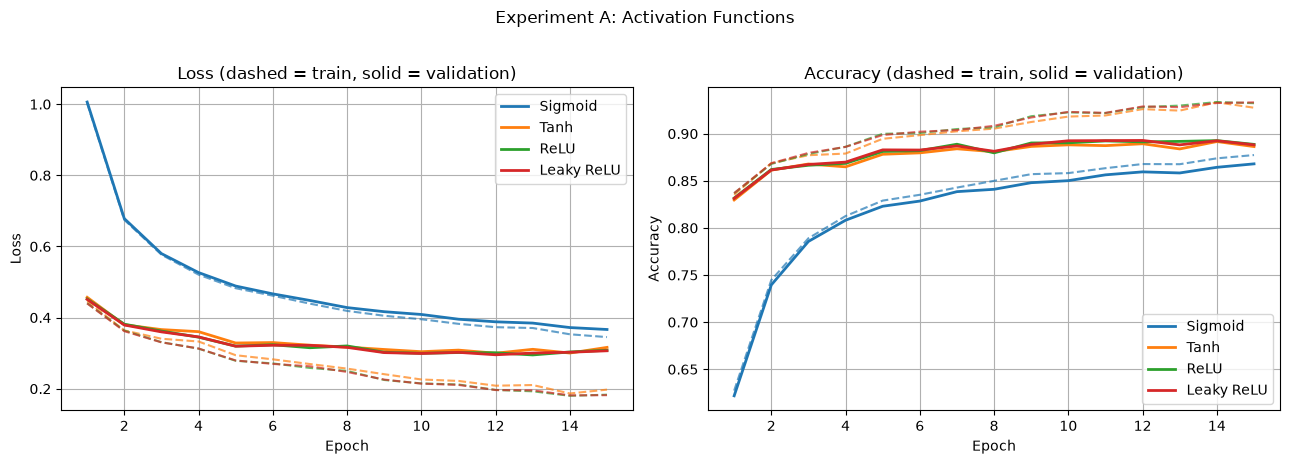

,Run,Epochs run,Final train acc,Final val acc,Best val acc,Best epoch,Acc gap (train - val),Test acc,Epochs to 85% val acc,Time (s)
0,Sigmoid,15,0.8773,0.8680,0.8680,15,0.0093,0.8699,10,114.0
1,Tanh,15,0.9276,0.8863,0.8917,12,0.0412,0.8861,2,103.6
2,ReLU,15,0.9324,0.8887,0.8927,13,0.0437,0.8904,2,98.9
3,Leaky ReLU,15,0.9332,0.8882,0.8928,12,0.0451,0.8870,2,123.0


In [8]:
# Experiment A: activation functions

results_A = {}
act_names = {"sigmoid": "Sigmoid", "tanh": "Tanh", "relu": "ReLU", "leaky_relu": "Leaky ReLU"}

for act, label in act_names.items():
    print(f"\n--- {label} ---")
    torch.manual_seed(42)                                    # same initialization seed for every run
    model = FeedforwardNet(activation=act)
    results_A[label] = train_model(model, train_loader, val_loader,
                                   optimizer_name="sgd_momentum", lr=0.01,
                                   epochs=15, test_loader=test_loader)


# Curves and comparison table

plot_histories(results_A, "Experiment A: Activation Functions")
summary_A = summarize(results_A)
display(summary_A)

### Experiment B: Optimizers

- **Compared:** Gradient Descent, SGD, SGD with momentum, RMSProp, Adam.
- **Fixed:** ReLU network (784-256-128-10), 15 epochs, same seed.
- **Gradient Descent** uses the **whole training set as one batch**, so it makes only one update per epoch (15 in total), while the others make about 422 updates per epoch.
- **Learning rates:** each optimizer uses a commonly suitable rate (SGD-type: 0.01 to 0.1; RMSProp and Adam: 0.001), since one rate does not suit all.
- **Look for:** convergence speed (epochs to reach 85% validation accuracy) and the final accuracy.


--- Gradient Descent ---
Epoch   1 | train loss 2.2630 acc 0.1328 | val loss 2.2627 acc 0.1378
Epoch   5 | train loss 2.0927 acc 0.5644 | val loss 2.0947 acc 0.5622
Epoch  10 | train loss 1.7074 acc 0.6309 | val loss 1.7139 acc 0.6330
Epoch  15 | train loss 1.2773 acc 0.6552 | val loss 1.2852 acc 0.6550

--- SGD ---
Epoch   1 | train loss 0.7122 acc 0.7523 | val loss 0.7151 acc 0.7448
Epoch   5 | train loss 0.4528 acc 0.8392 | val loss 0.4612 acc 0.8280
Epoch  10 | train loss 0.3906 acc 0.8599 | val loss 0.4054 acc 0.8552
Epoch  15 | train loss 0.3528 acc 0.8748 | val loss 0.3715 acc 0.8693

--- SGD + Momentum ---
Epoch   1 | train loss 0.4404 acc 0.8368 | val loss 0.4525 acc 0.8317
Epoch   5 | train loss 0.2786 acc 0.8999 | val loss 0.3198 acc 0.8812
Epoch  10 | train loss 0.2149 acc 0.9226 | val loss 0.2996 acc 0.8903
Epoch  15 | train loss 0.1833 acc 0.9324 | val loss 0.3081 acc 0.8887

--- RMSProp ---
Epoch   1 | train loss 0.3702 acc 0.8649 | val loss 0.3855 acc 0.8570
Epoch   5 

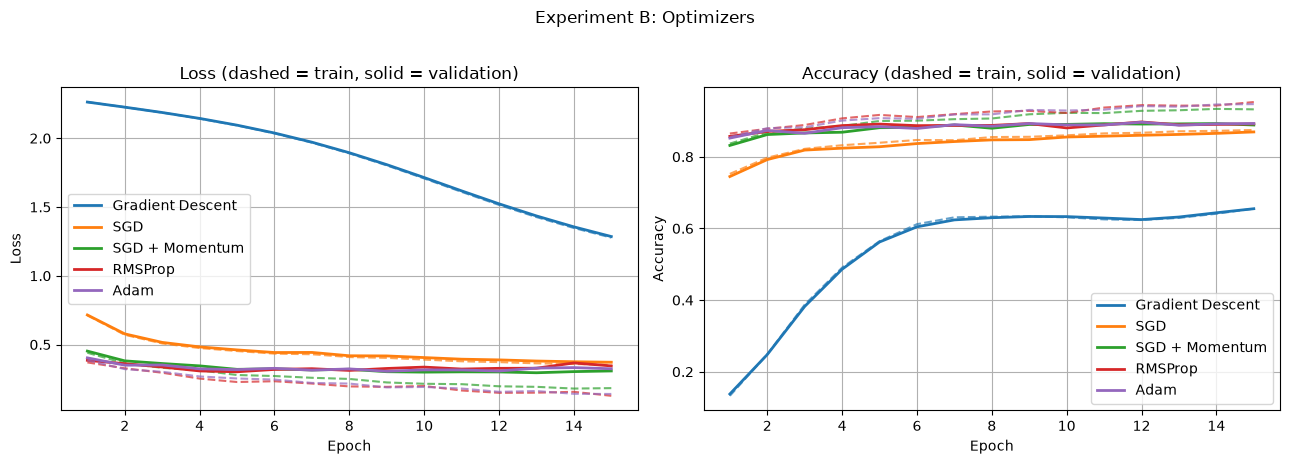

,Run,Epochs run,Final train acc,Final val acc,Best val acc,Best epoch,Acc gap (train - val),Test acc,Epochs to 85% val acc,Time (s)
0,Gradient Descent,15,0.6552,0.6550,0.6550,15,0.0002,0.6556,not reached,255.4
1,SGD,15,0.8748,0.8693,0.8693,15,0.0055,0.8664,10,471.5
2,SGD + Momentum,15,0.9324,0.8887,0.8927,13,0.0437,0.8904,2,92.0
3,RMSProp,15,0.9528,0.8918,0.8972,5,0.0610,0.9019,1,191.9
4,Adam,15,0.9469,0.8928,0.8965,9,0.0541,0.8969,1,197.7


In [9]:
# Experiment B: optimizers

# Full-batch loader for Gradient Descent (one update per epoch)
full_batch_loader = DataLoader(train_ds, batch_size=len(train_ds), shuffle=False)

optimizer_configs = {
    "Gradient Descent": ("gd", 0.1, full_batch_loader),
    "SGD": ("sgd", 0.01, train_loader),
    "SGD + Momentum": ("sgd_momentum", 0.01, train_loader),
    "RMSProp": ("rmsprop", 0.001, train_loader),
    "Adam": ("adam", 0.001, train_loader),
}

results_B = {}
for label, (opt_name, lr, loader) in optimizer_configs.items():
    print(f"\n--- {label} ---")
    torch.manual_seed(42)
    model = FeedforwardNet(activation="relu")
    results_B[label] = train_model(model, loader, val_loader,
                                   optimizer_name=opt_name, lr=lr,
                                   epochs=15, test_loader=test_loader)


# Curves and comparison table

plot_histories(results_B, "Experiment B: Optimizers")
summary_B = summarize(results_B)
display(summary_B)

### Experiment C: Dropout and Overfitting

- **Setup built to overfit:** only **2,000 training images** and a larger network (784-512-512-256-10), trained for 40 epochs with Adam.
- **Compared:** no dropout vs dropout of 0.2 vs 0.5.
- **Validation** uses the full 6,000-image validation set.
- **Look for:** the gap between the dashed (train) and solid (validation) curves. Without dropout, training loss keeps falling while validation loss rises, which signals overfitting. Dropout should narrow the gap.


--- No dropout ---
Epoch   1 | train loss 0.6555 acc 0.7325 | val loss 0.6985 acc 0.7172
Epoch   5 | train loss 0.3851 acc 0.8570 | val loss 0.5430 acc 0.8050
Epoch  10 | train loss 0.2022 acc 0.9260 | val loss 0.5747 acc 0.8163
Epoch  15 | train loss 0.1382 acc 0.9430 | val loss 0.6337 acc 0.8198
Epoch  20 | train loss 0.1371 acc 0.9510 | val loss 0.7497 acc 0.8195
Epoch  25 | train loss 0.0817 acc 0.9740 | val loss 0.7279 acc 0.8213
Epoch  30 | train loss 0.0714 acc 0.9790 | val loss 0.7383 acc 0.8282
Epoch  35 | train loss 0.0312 acc 0.9905 | val loss 0.9194 acc 0.8320
Epoch  40 | train loss 0.0336 acc 0.9900 | val loss 0.9245 acc 0.8275

--- Dropout 0.2 ---
Epoch   1 | train loss 0.7208 acc 0.7385 | val loss 0.7554 acc 0.7175
Epoch   5 | train loss 0.4209 acc 0.8370 | val loss 0.5586 acc 0.7965
Epoch  10 | train loss 0.2692 acc 0.9020 | val loss 0.5469 acc 0.8073
Epoch  15 | train loss 0.2014 acc 0.9225 | val loss 0.5884 acc 0.8207
Epoch  20 | train loss 0.1820 acc 0.9285 | val lo

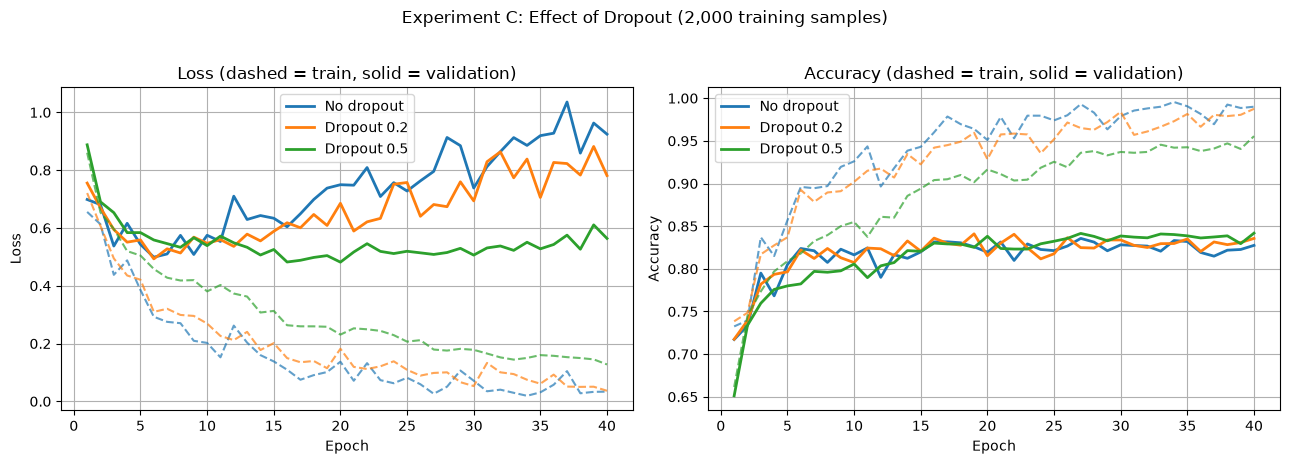

,Run,Epochs run,Final train acc,Final val acc,Best val acc,Best epoch,Acc gap (train - val),Test acc,Epochs to 85% val acc,Time (s)
0,No dropout,40,0.9900,0.8275,0.8357,6,0.1625,0.8298,not reached,88.7
1,Dropout 0.2,40,0.9875,0.8357,0.8410,6,0.1518,0.8358,not reached,98.5
2,Dropout 0.5,40,0.9555,0.8418,0.8418,20,0.1137,0.8404,not reached,107.3


In [10]:
# Experiment C: dropout

from torch.utils.data import Subset

# Small training subset (first 2000 images of the training split) to force overfitting
small_train = Subset(train_ds, range(2000))
small_train_loader = DataLoader(small_train, batch_size=64, shuffle=True)

results_C = {}
for p in [0.0, 0.2, 0.5]:
    label = "No dropout" if p == 0 else f"Dropout {p}"
    print(f"\n--- {label} ---")
    torch.manual_seed(42)
    model = FeedforwardNet(hidden_dims=(512, 512, 256), activation="relu", dropout=p)
    results_C[label] = train_model(model, small_train_loader, val_loader,
                                   optimizer_name="adam", lr=1e-3,
                                   epochs=40, test_loader=test_loader)


# Curves and comparison table

plot_histories(results_C, "Experiment C: Effect of Dropout (2,000 training samples)")
summary_C = summarize(results_C)
display(summary_C)

### Experiment D: MSE vs Binary Cross Entropy

- **Binary task:** classify **T-shirt/top (class 0)** vs **Shirt (class 6)**, two visually similar classes, so the task is not trivial.
- **Compared:** MSE (on the sigmoid output) vs BCE (`BCEWithLogitsLoss`, which applies the sigmoid internally for numerical stability).
- **Fixed:** network 784-128-64-1, plain SGD (lr = 0.05), 20 epochs, same seed.
- **Note:** loss **values** from MSE and BCE are on different scales, so compare **accuracy** and **convergence speed**, not the loss numbers.
- **Look for:** BCE should give stronger gradients when the model is confidently wrong, so it should learn faster.

Binary samples: 12000 | Class balance: 0.5

--- MSE ---
Epoch   1 | train loss 0.1297 acc 0.8281 | val loss 0.1316 acc 0.8163
Epoch   5 | train loss 0.1048 acc 0.8561 | val loss 0.1107 acc 0.8492
Epoch  10 | train loss 0.0960 acc 0.8697 | val loss 0.1040 acc 0.8579
Epoch  15 | train loss 0.0912 acc 0.8754 | val loss 0.1020 acc 0.8567
Epoch  20 | train loss 0.0862 acc 0.8827 | val loss 0.0993 acc 0.8600

--- BCE ---
Epoch   1 | train loss 0.3627 acc 0.8380 | val loss 0.3706 acc 0.8283
Epoch   5 | train loss 0.2988 acc 0.8670 | val loss 0.3194 acc 0.8575
Epoch  10 | train loss 0.2681 acc 0.8823 | val loss 0.3060 acc 0.8650
Epoch  15 | train loss 0.2480 acc 0.8904 | val loss 0.3038 acc 0.8617
Epoch  20 | train loss 0.2382 acc 0.9005 | val loss 0.3124 acc 0.8575


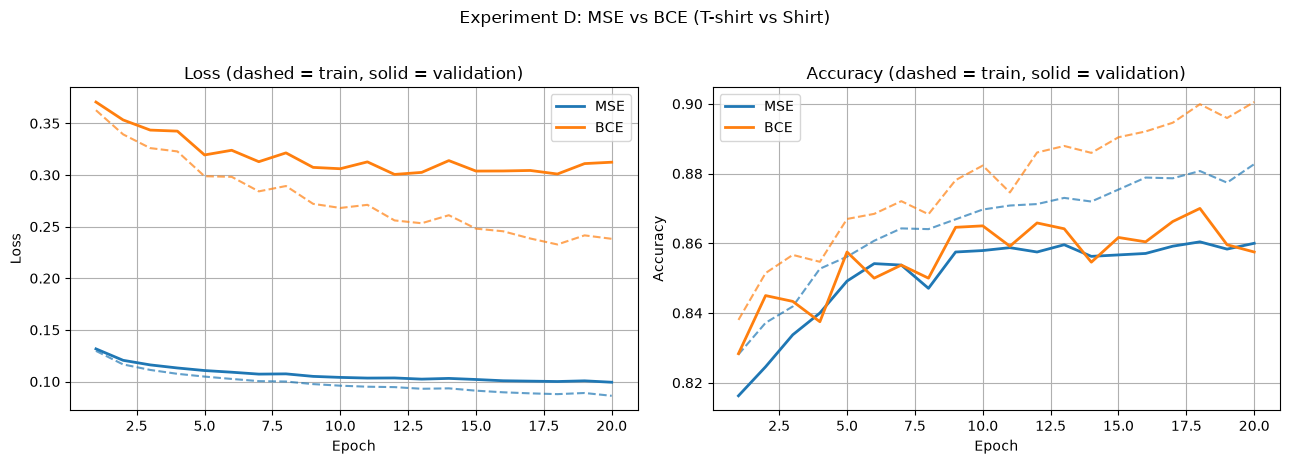

,Run,Epochs run,Final train acc,Final val acc,Best val acc,Best epoch,Acc gap (train - val),Test acc,Epochs to 85% val acc,Time (s)
0,MSE,20,0.8827,0.8600,0.8604,20,0.0227,None,6,51.3
1,BCE,20,0.9005,0.8575,0.8700,12,0.0430,None,5,46.9


In [11]:
# Experiment D: MSE vs BCE on a binary task

# Build the binary dataset: T-shirt/top (0) vs Shirt (6) -> labels 0 / 1
mask = (y_train_full == 0) | (y_train_full == 6)
Xb = X_train_full[mask]
yb_bin = (y_train_full[mask] == 6).float()
print("Binary samples:", len(Xb), "| Class balance:", yb_bin.mean().item())


# 80 / 20 train-validation split
perm = torch.randperm(len(Xb), generator=torch.Generator().manual_seed(42))
n_tr = int(0.8 * len(Xb))
tr_idx, va_idx = perm[:n_tr], perm[n_tr:]

bin_train_loader = DataLoader(TensorDataset(Xb[tr_idx], yb_bin[tr_idx]), batch_size=128, shuffle=True)
bin_val_loader = DataLoader(TensorDataset(Xb[va_idx], yb_bin[va_idx]), batch_size=128)


# Train with each loss

results_D = {}
for label, loss_type in [("MSE", "mse"), ("BCE", "bce")]:
    print(f"\n--- {label} ---")
    torch.manual_seed(42)
    model = FeedforwardNet(hidden_dims=(128, 64), num_outputs=1, activation="relu")
    results_D[label] = train_model(model, bin_train_loader, bin_val_loader,
                                   optimizer_name="sgd", lr=0.05,
                                   epochs=20, loss_type=loss_type)


# Curves and comparison table

plot_histories(results_D, "Experiment D: MSE vs BCE (T-shirt vs Shirt)")
summary_D = summarize(results_D)
display(summary_D)

### Experiment E: Batch Normalization and Early Stopping

- **Setup:** the same overfitting setup as Experiment C (2,000 training images, 784-512-512-256-10, Adam, up to 30 epochs). Run Experiment C first, since this reuses its `small_train_loader`.
- **Compared:**
  - **No BN:** the baseline.
  - **Batch Norm:** a `BatchNorm1d` layer after each linear layer.
  - **Early stopping:** the baseline with `patience=5`, which stops when validation loss has not improved for 5 epochs and restores the best weights.
- **Look for:** batch norm should make early epochs converge faster; early stopping should halt before the validation loss climbs, and its test accuracy comes from the best epoch.


--- No BN ---
Epoch   1 | train loss 0.6555 acc 0.7325 | val loss 0.6985 acc 0.7172
Epoch   5 | train loss 0.3851 acc 0.8570 | val loss 0.5430 acc 0.8050
Epoch  10 | train loss 0.2022 acc 0.9260 | val loss 0.5747 acc 0.8163
Epoch  15 | train loss 0.1382 acc 0.9430 | val loss 0.6337 acc 0.8198
Epoch  20 | train loss 0.1371 acc 0.9510 | val loss 0.7497 acc 0.8195
Epoch  25 | train loss 0.0817 acc 0.9740 | val loss 0.7279 acc 0.8213
Epoch  30 | train loss 0.0714 acc 0.9790 | val loss 0.7383 acc 0.8282

--- Batch Norm ---
Epoch   1 | train loss 0.5566 acc 0.7920 | val loss 0.6483 acc 0.7628
Epoch   5 | train loss 0.2522 acc 0.9080 | val loss 0.5716 acc 0.7877
Epoch  10 | train loss 0.1502 acc 0.9460 | val loss 0.6458 acc 0.8077
Epoch  15 | train loss 0.0554 acc 0.9860 | val loss 0.6098 acc 0.8273
Epoch  20 | train loss 0.0354 acc 0.9895 | val loss 0.7034 acc 0.8167
Epoch  25 | train loss 0.0430 acc 0.9855 | val loss 0.7838 acc 0.8133
Epoch  30 | train loss 0.0134 acc 0.9975 | val loss 0.7

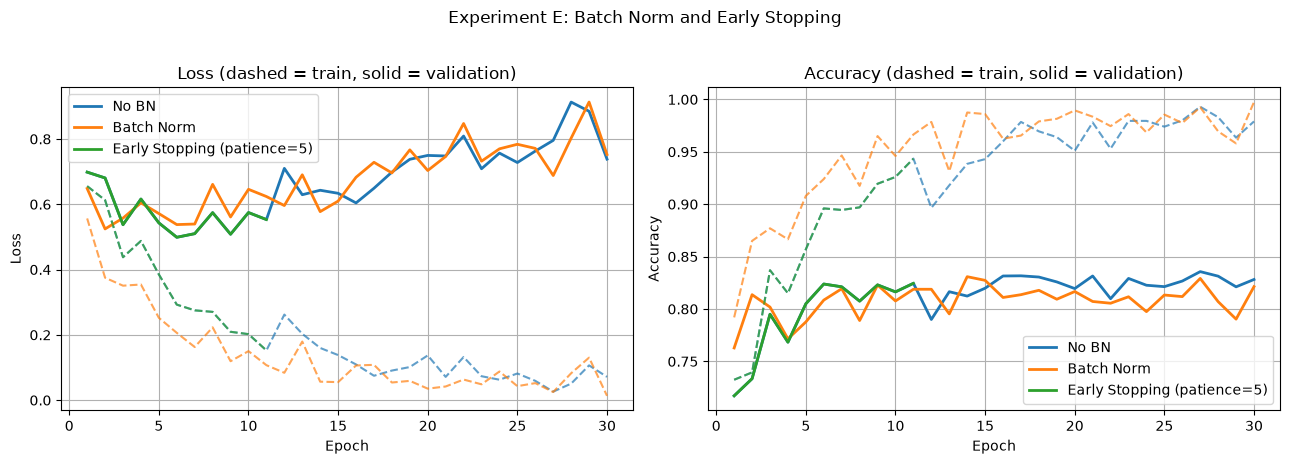

,Run,Epochs run,Final train acc,Final val acc,Best val acc,Best epoch,Acc gap (train - val),Test acc,Epochs to 85% val acc,Time (s)
0,No BN,30,0.9790,0.8282,0.8357,6,0.1508,0.8269,not reached,74.0
1,Batch Norm,30,0.9975,0.8213,0.8308,2,0.1762,0.8223,not reached,62.9
2,Early Stopping (patience=5),11,0.9435,0.8245,0.8245,6,0.1190,0.8231,not reached,21.9


In [12]:
# Experiment E: batch normalization and early stopping

e_configs = {
    "No BN": dict(batch_norm=False, patience=None),
    "Batch Norm": dict(batch_norm=True, patience=None),
    "Early Stopping (patience=5)": dict(batch_norm=False, patience=5),
}

results_E = {}
for label, cfg in e_configs.items():
    print(f"\n--- {label} ---")
    torch.manual_seed(42)
    model = FeedforwardNet(hidden_dims=(512, 512, 256), activation="relu",
                           batch_norm=cfg["batch_norm"])
    results_E[label] = train_model(model, small_train_loader, val_loader,
                                   optimizer_name="adam", lr=1e-3,
                                   epochs=30, patience=cfg["patience"],
                                   test_loader=test_loader)


# Curves and comparison table

plot_histories(results_E, "Experiment E: Batch Norm and Early Stopping")
summary_E = summarize(results_E)
display(summary_E)

## Step 5: Final Analysis and Conclusions

### 1. Overall Performance Summary
- The best performing model overall (selected strictly by Cross-Validation F1) was **Random Forest** tuned via **Grid Search**, achieving a CV F1 score of **0.7835 (+/- 0.0223)** and a held-out Test F1 of **0.7552** (Test Accuracy: 0.8045).
- Baseline scores without tuning were:
  - Random Forest: CV F1 = **0.7562** (Test F1 = 0.7391)
  - XGBoost: CV F1 = **0.7513** (Test F1 = 0.7591)
  - SVM: CV F1 = **0.7643** (Test F1 = 0.7910)
- Tuning produced an improvement of **+0.0273** CV F1 points for Random Forest (rising from 0.7562 to 0.7835) and **+0.0276** for XGBoost (from 0.7513 to 0.7789), while SVM baseline was already strong and improved slightly under Random Search (from 0.7643 to 0.7726).

### 2. Search Methods Comparison (Grid vs Random vs Bayesian)
- **Grid Search:** Thorough for small spaces, but computationally expensive when evaluating multiple combinations. In our run, it took **28.68s** (32 candidates) for Random Forest and **6.63s** (64 candidates) for XGBoost.
- **Random Search:** Significantly faster while exploring continuous parameter ranges, taking only **7.24s** (5 candidates) for Random Forest to achieve an F1 of **0.7792**, closely matching Grid Search with far fewer evaluations.
- **Optuna (Bayesian Search):** The most sample-efficient method. Its TPE sampler converged quickly in **0.80s** for XGBoost and **4.99s** for Random Forest, achieving competitive validation scores with minimal search time.

### 3. Overfitting Analysis (Train-CV Gap)
- The unconstrained default baseline models showed large train-CV gaps of **0.2272** for Random Forest and **0.2247** for XGBoost, demonstrating severe memorization of the training set.
- Hyperparameter tuning successfully addressed this: constraining tree complexity (`max_depth=3`, `min_samples_leaf`, and subsampling/regularization) reduced the Train-CV gap down to **0.0549** for Random Forest (Grid) and **0.0262** for XGBoost (Random), significantly improving generalization.

### 4. Limitations
- **Small Test Set:** With only 179 rows in the test partition, a difference of 1-2 misclassifications shifts test accuracy/F1 by around 1%.
- **Decision Rule:** Selecting the final configuration by highest CV score (0.7835 for Random Forest Grid) rather than test score was crucial to maintain integrity and prevent test-set data snooping.